# Philippine Cybersecurity Job Salary Regression
**MAC1 Final Project, Group 11**




## Stage 1: Problem Definition
- **Task type:** Regression. We predict a number (the monthly salary).
- **Target variable:** Monthly salary in PHP (`salary`).
- **Objective:** Predict the monthly salary of a cybersecurity job in NCR.
- **Success metric:** Mean Squared Error (MSE). A lower MSE is better. We also show RMSE, MAE and R2 because they are easier to read.

## Stage 2: Data Collection
No public dataset fit our topic, so we collected the data by hand. Our instructor allowed this.

- **Sources:** Job posts on JobStreet, Glassdoor, Kalibrr and Bossjob. Salary guides from Michael Page and Robert Walters.
- **Date retrieved:** Nov3-Nov4 2026
- **File:** `philippines_cybersecurity_jobsalary.csv` (1,542 rows and 8 columns). This is the raw data, before cleaning.

**Data dictionary**

| Column | Type | Meaning |
|---|---|---|
| `company_name` | Text | Name of the company that posted the job. Some are missing. |
| `job_title` | Text | Job title in the post. |
| `salary` | Number (target) | Monthly salary in PHP. |
| `experience_level` | Category | Entry-Level, Mid-Level, Senior, Manager or Executive. |
| `employment_type` | Category | Full-Time, Contract or Part-Time. |
| `work_year` | Number | Year of the post. We do not use it. |
| `company_location` | Text | Location text, for example "Makati City, Metro Manila (Hybrid)". |
| `company_size` | Category | Small, Medium, Large or Enterprise. Many are missing. |

Columns we make later: `work_arrangement` (Onsite, Hybrid or Remote), `city`, `salary_capped`, `is_manager_title`, `is_engineer`, `is_analyst` and `title_cluster`.

In [2]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, silhouette_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans

PATH = "philippines_cybersecurity_jobsalary.csv"   # the raw data file. Keep it in the same folder as this notebook.
df = pd.read_csv(PATH)
print("Raw shape:", df.shape)
print(df.head())

Raw shape: (1542, 8)
                         company_name                          job_title  \
0     Pluxee Philippines Incorporated        Local Cybersecurity Officer   
1                  Private Advertiser               SOC Analyst (Tier 1)   
2  Strategem Ventures Management Inc.            Cyber Security Engineer   
3                 Asiatel Outsourcing             Cybersecurity Engineer   
4                              Emapta  Cyber Security Operations Analyst   

   salary experience_level employment_type work_year  \
0   75000        Mid-Level       Full time      2026   
1   27500      Entry-Level   Contract/Temp      2026   
2   21500      Entry-Level       Full time      2026   
3   57500        Mid-Level       Full time      2026   
4  200000           Senior       Full time      2026   

                          company_location company_size  
0       Makati City, Metro Manila (Hybrid)       Medium  
1                    Metro Manila (Remote)   Enterprise  
2          

## Stage 3: Data Cleaning and Preprocessing
The raw data is messy, like real data. In this stage we do these steps:
1. Look at the problems in the raw data.
2. Standardize the text and the salary.
3. Get `work_arrangement` and `city` from the location, and keep NCR only.
4. Remove duplicates and rows with no salary or no job title. Fill the missing categories.
5. Cap the outliers.

### 3.1 Look at the raw data

In [3]:
print("Missing values per column:")
print(df.isna().sum())
print("\nExact duplicate rows:", df.duplicated().sum())
print("\nexperience_level has messy spellings:")
print(df["experience_level"].value_counts(dropna=False))
print("\nemployment_type has messy spellings:")
print(df["employment_type"].value_counts(dropna=False))

Missing values per column:
company_name        116
job_title             1
salary              686
experience_level      1
employment_type     115
work_year             0
company_location      8
company_size        599
dtype: int64

Exact duplicate rows: 310

experience_level has messy spellings:
experience_level
Mid-level        509
Senior           468
Mid-Level        255
Entry-Level       93
Entry-level       88
Not Specified     68
Executive         23
Senior-level      18
Manager           11
Associate          3
Internship         3
Supervisor         1
NaN                1
Full-time          1
Name: count, dtype: int64

employment_type has messy spellings:
employment_type
Full-time        784
Full time        470
NaN              115
Full-Time         54
Not Specified     40
Contract          38
Permanent         25
Fixed term         5
Contract/Temp      4
Part-time          4
Part time          1
Part-Time          1
Internship         1
Name: count, dtype: int64


**What we see:** Many values are missing (`salary` 686, `company_size` 599, `company_name` 116, `employment_type` 115). There are 310 exact duplicate rows. The same thing is written in different ways, for example "Mid-level" (509) and "Mid-Level" (255), or "Full-time" and "Full time". Some values say "Not Specified", which also means missing.

### 3.2 Standardize the text and the salary

In [4]:
df = df.copy()
text_cols = ["company_name", "job_title", "experience_level",
             "employment_type", "company_location", "company_size"]
for c in text_cols:
    df[c] = df[c].astype("string").str.strip()
df = df.replace({"Not Specified": pd.NA})

df["salary"] = pd.to_numeric(df["salary"], errors="coerce")   

exp_map = {
    "mid-level": "Mid-Level", "entry-level": "Entry-Level",
    "senior": "Senior", "senior-level": "Senior",
    "executive": "Executive", "manager": "Manager",
    "supervisor": "Manager", "associate": "Entry-Level",
    "internship": "Entry-Level",
}
df["experience_level"] = df["experience_level"].str.lower().map(exp_map)

emp_map = {
    "full-time": "Full-Time", "full time": "Full-Time", "permanent": "Full-Time",
    "contract": "Contract", "contract/temp": "Contract", "fixed term": "Contract",
    "part-time": "Part-Time", "part time": "Part-Time", "internship": "Part-Time",
}
df["employment_type"] = df["employment_type"].str.lower().map(emp_map)

### 3.3 Work arrangement and city (keep NCR only)
We read the location text, for example "Makati City, Metro Manila (Hybrid)". If the text has "Remote" or "Hybrid", we use it for `work_arrangement`, and the rest is "Onsite". We look for an NCR city name in the same text to make `city`. Rows with no NCR city are removed, so the data is NCR only (1,542 → 1,364 rows).

In [5]:
loc = df["company_location"].fillna("")
df["work_arrangement"] = np.select(
    [loc.str.contains("Remote", case=False), loc.str.contains("Hybrid", case=False)],
    ["Remote", "Hybrid"], default="Onsite")

ncr_cities = {
    "Makati": "Makati", "Taguig": "Taguig", "BGC": "Taguig", "Fort Bonifacio": "Taguig",
    "Pasig": "Pasig", "Ortigas": "Pasig", "Mandaluyong": "Mandaluyong",
    "Quezon": "Quezon City", "Manila": "Manila", "Paranaque": "Paranaque",
    "Parañaque": "Paranaque", "Pasay": "Pasay", "Muntinlupa": "Muntinlupa",
    "Alabang": "Muntinlupa", "Caloocan": "Caloocan", "Las Pinas": "Las Pinas",
    "Las Piñas": "Las Pinas", "Marikina": "Marikina", "Valenzuela": "Valenzuela",
    "Malabon": "Malabon", "Navotas": "Navotas", "San Juan": "San Juan",
    "Pateros": "Pateros", "Metro Manila": "Metro Manila (unspecified)",
}
def find_city(s):
    for key, val in ncr_cities.items():
        if re.search(key, s, flags=re.I):
            return val
    return np.nan                    # not NCR / unrecognized location

df["city"] = loc.apply(find_city)
df = df[df["city"].notna()]          # keep NCR rows only
print("After NCR filter:", df.shape)

After NCR filter: (1364, 10)


### 3.4 Duplicates, missing values and unneeded columns
We removed the columns we do not need (`company_location`, `work_year`) and the duplicate rows (1,364 → 1,041 rows). We also removed the posts with no salary or no job title (475 rows), because the target must exist before modeling. Missing values in the category columns (company size, employment type, experience level) were filled with "Unknown", so we keep those rows. `company_name` was left as it is (53 empty), because it is not used as a feature.

| Step | Rows left |
|---|---|
| Raw data | 1,542 |
| NCR only | 1,364 |
| After removing duplicates | 1,041 |
| After removing rows with no salary or no title (model-ready) | 566 |

The final model-ready dataset has 566 rows from 240 companies.

In [6]:
df = df.drop(columns=["company_location", "work_year"])   
df = df.drop_duplicates()
print("After dedup:", df.shape)

df = df.dropna(subset=["salary"])    # the target variable must exist
df["company_size"] = df["company_size"].fillna("Unknown")
df["employment_type"] = df["employment_type"].fillna("Unknown")
df["experience_level"] = df["experience_level"].fillna("Unknown")
df = df.dropna(subset=["job_title"]).reset_index(drop=True)
print("Model-ready rows:", df.shape)
print(df.isna().sum())

After dedup: (1041, 8)
Model-ready rows: (566, 8)
company_name        53
job_title            0
salary               0
experience_level     0
employment_type      0
company_size         0
work_arrangement     0
city                 0
dtype: int64


### 3.5 Outliers (IQR capping)
We used the Interquartile Range (IQR) of the salary to find extreme values (bounds: 0 to 182,500 PHP; 22 outliers). We cap them at the upper bound and save the result as `salary_capped`. We use it for the charts in Stage 4. For the models, the target is capped again later (Stage 5) with bounds from the training set only, to prevent data leakage.

In [7]:
q1, q3 = df["salary"].quantile([0.25, 0.75])
iqr = q3 - q1
low, high = max(q1 - 1.5 * iqr, 0), q3 + 1.5 * iqr
print(f"IQR bounds: {low:,.0f} - {high:,.0f}; outliers: {((df.salary<low)|(df.salary>high)).sum()}")
df["salary_capped"] = df["salary"].clip(low, high)   # capped salary is used as the target variable

IQR bounds: 0 - 182,500; outliers: 22


---
## Stage 4: Exploratory Data Analysis (EDA)
We make 6 charts. Under each chart we write what we see.

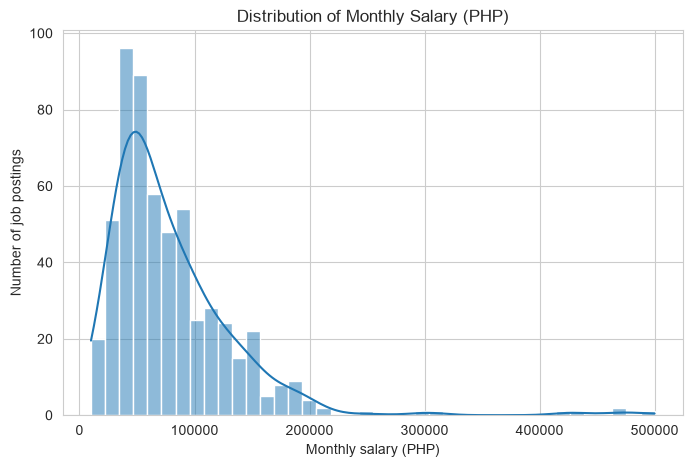

In [8]:
sns.set_style("whitegrid")

plt.figure(figsize=(8, 5))
sns.histplot(df["salary"], bins=40, kde=True)
plt.title("Distribution of Monthly Salary (PHP)")
plt.xlabel("Monthly salary (PHP)")
plt.ylabel("Number of job postings")
plt.show()

**Interpretation:** The salary distribution histogram is right-skewed. Most postings fall around 40,000–60,000 PHP, with a long tail reaching about 500,000 PHP. Only a small number of postings reach very high salaries; 22 were flagged as outliers by the IQR rule.

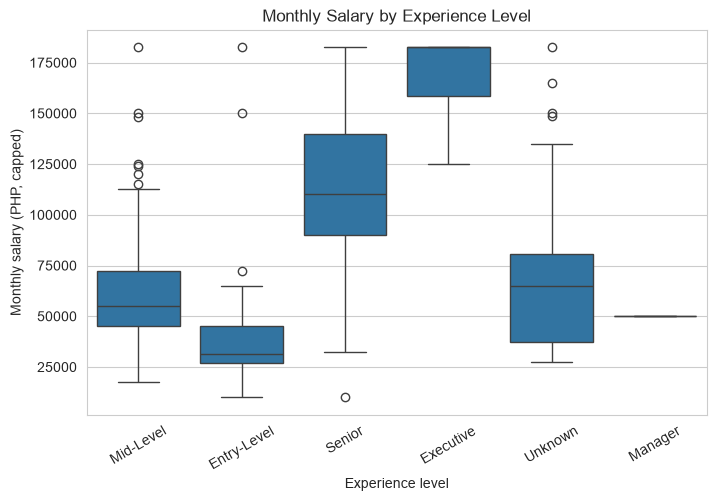

In [9]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="experience_level", y="salary_capped")
plt.title("Monthly Salary by Experience Level")
plt.xlabel("Experience level")
plt.ylabel("Monthly salary (PHP, capped)")
plt.xticks(rotation=30)
plt.show()

**Interpretation:** The boxplot shows that median salary rises with experience level: about 31,500 PHP for Entry-Level, 55,000 for Mid-Level, 110,000 for Senior, and 182,500 (the cap) for Executive. However, Executive has only 7 postings and Manager has only 1 (about 50,000 PHP), so the results for these two levels are not reliable.

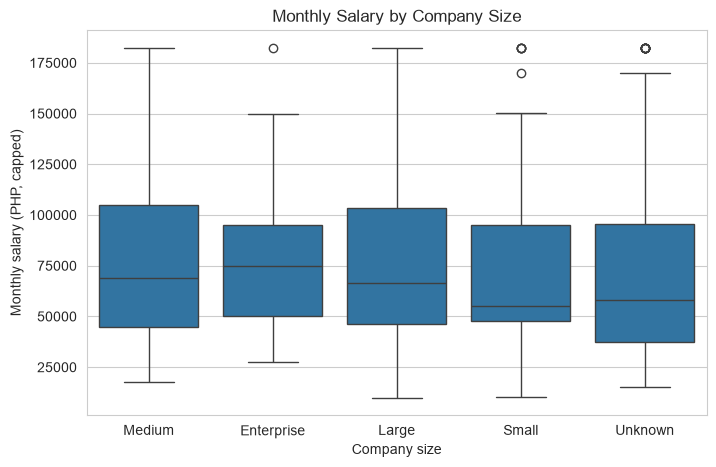

In [10]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="company_size", y="salary_capped")
plt.title("Monthly Salary by Company Size")
plt.xlabel("Company size")
plt.ylabel("Monthly salary (PHP, capped)")
plt.show()

**Interpretation:** Median salary ranges from about 55,000 PHP (Small) to 75,000 PHP (Enterprise), but the boxes overlap heavily across all company sizes. This suggests that company size has only a modest effect on cybersecurity compensation in the NCR.

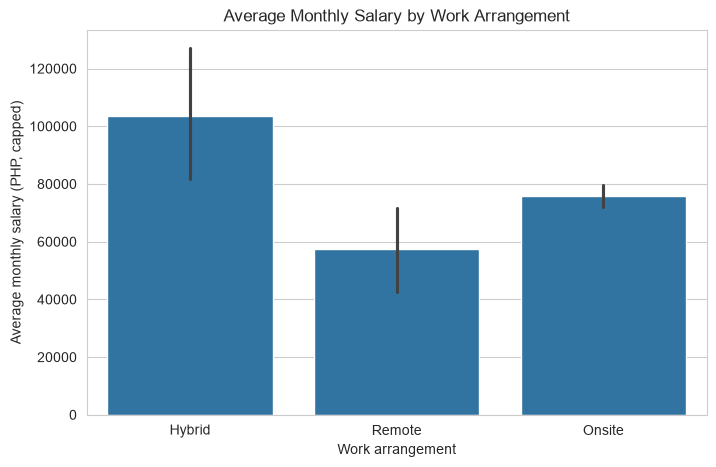

In [11]:
plt.figure(figsize=(8, 5))
sns.barplot(data=df, x="work_arrangement", y="salary_capped")
plt.title("Average Monthly Salary by Work Arrangement")
plt.xlabel("Work arrangement")
plt.ylabel("Average monthly salary (PHP, capped)")
plt.show()

**Interpretation:** Hybrid roles have the highest average salary (about 103,000 PHP), followed by Onsite (about 75,000 PHP) and Remote (about 57,000 PHP). However, the dataset is dominated by Onsite postings (550), with only 11 Hybrid and 5 Remote postings, so the Hybrid and Remote averages (and their wide error bars) should be read with caution.

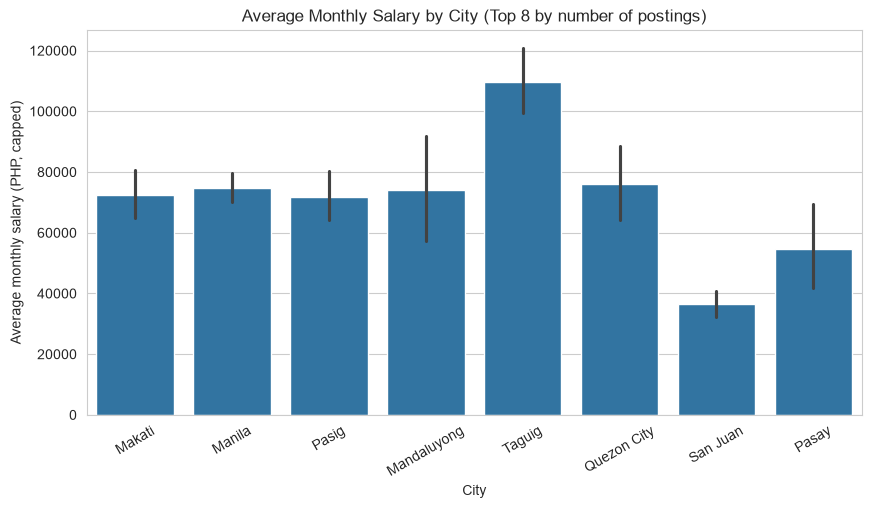

In [12]:
top_city = df["city"].value_counts().head(8).index

plt.figure(figsize=(10, 5))
sns.barplot(data=df[df["city"].isin(top_city)], x="city", y="salary_capped")
plt.title("Average Monthly Salary by City (Top 8 by number of postings)")
plt.xlabel("City")
plt.ylabel("Average monthly salary (PHP, capped)")
plt.xticks(rotation=30)
plt.show()

**Interpretation:** Taguig has the highest average salary among NCR cities (about 110,000 PHP), well above the others. Quezon City (about 76,000 PHP), Manila, Mandaluyong, Makati, and Pasig are similar at around 72,000–75,000 PHP, while San Juan is the lowest (about 36,000 PHP, based on only 7 postings). Taguig may pay more because of its many corporate offices, but our data cannot prove this. Note that the ‘Manila’ group is too large because our city list checks ‘Manila’ first, so many ‘<city>, Metro Manila’ postings were counted as Manila.”

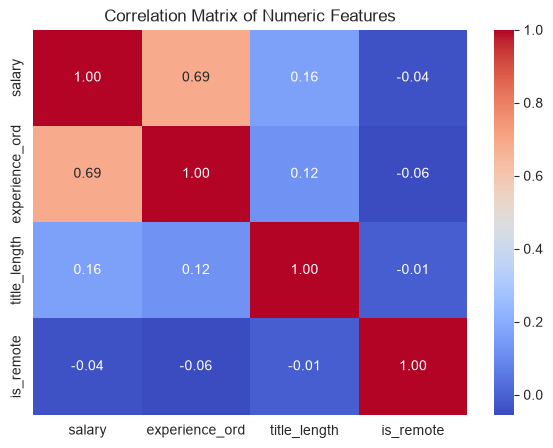

In [13]:
ord_map = {"Unknown": np.nan, "Entry-Level": 1, "Mid-Level": 2,
           "Senior": 3, "Manager": 4, "Executive": 5}
corr_df = pd.DataFrame({
    "salary": df["salary_capped"],
    "experience_ord": df["experience_level"].map(ord_map),
    "title_length": df["job_title"].str.len(),
    "is_remote": (df["work_arrangement"] == "Remote").astype(int),
})

plt.figure(figsize=(7, 5))
sns.heatmap(corr_df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Matrix of Numeric Features")
plt.show()

**Interpretation:** The correlation matrix shows that experience level has the strongest positive correlation with capped salary (0.69). Job title length shows only a weak positive correlation (0.16), and remote work shows almost none (-0.04).

---
## Stage 5: Feature Engineering and Selection
- **New features:** From the job title we make `is_manager_title`, `is_engineer` and `is_analyst` (1 = yes, 0 = no).
- **One-Hot Encoding:** `experience_level`, `employment_type`, `company_size`, `work_arrangement` and `city` are text, so we change them to 0/1 columns (with `drop_first=True`). This gives 26 columns.
- **Scaling:** `StandardScaler` puts all columns on the same scale. We use the scaled data for Linear Regression. The Random Forest uses the unscaled data.
- **80/20 split:** 452 rows for training and 114 rows for testing. We split first.
- **No data leakage:** The one-hot columns, the outlier bounds and the scaler learn from the training data only.

### 5.1 New features and the 80/20 split

In [14]:
#Feature creation + strict 80/20 split
t = df["job_title"].str.lower()
df["is_manager_title"] = t.str.contains("manager|head|director|chief|ciso|lead").astype(int)
df["is_engineer"] = t.str.contains("engineer|architect").astype(int)
df["is_analyst"] = t.str.contains("analyst").astype(int)

cat_cols = ["experience_level", "employment_type", "company_size", "work_arrangement", "city"]
num_cols = ["is_manager_title", "is_engineer", "is_analyst"]

train_df, test_df = train_test_split(df, test_size=0.20, random_state=42)

### 5.2 Encoding, target capping and scaling (training data only)
We applied one-hot encoding to the categorical features and made the test columns match the training columns. We clipped the target with bounds from the training set only, and fit `StandardScaler` on the training data only.

In [15]:
#Encode, cap outliers, and scale using TRAINING data only
X_train = pd.get_dummies(train_df[cat_cols + num_cols], columns=cat_cols, drop_first=True)
X_test = pd.get_dummies(test_df[cat_cols + num_cols], columns=cat_cols, drop_first=True)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)   # match training columns

q1, q3 = train_df["salary"].quantile([0.25, 0.75])
iqr = q3 - q1
low, high = max(q1 - 1.5 * iqr, 0), q3 + 1.5 * iqr               # bounds from training set only
y_train = train_df["salary"].clip(low, high)
y_test = test_df["salary"].clip(low, high)

scaler = StandardScaler().fit(X_train)
X_train_s, X_test_s = scaler.transform(X_train), scaler.transform(X_test)
print(X_train.shape, X_test.shape)

(452, 26) (114, 26)


## Stage 6 and 7: Model Selection and Model Training
We train two algorithms on the same split:
- **Linear Regression:** A simple model. It finds a straight-line link between the features and the salary. It is easy to explain.
- **Random Forest:** Many decision trees. The answer is the average of all the trees. It can find patterns that are not straight lines.

How to read the metrics: **MSE** is the average of the squared mistakes (lower is better, and this is our main metric). **RMSE** is the square root of MSE, in PHP. **MAE** is the average mistake in PHP. **R2** is 1 for a perfect model and 0 for a model that only guesses the average.

We defined an evaluation function that trains a model, predicts the test set, and prints the metrics.

In [16]:
def evaluate(name, model, Xtr, Xte):
    model.fit(Xtr, y_train)
    pred = model.predict(Xte)
    mse = mean_squared_error(y_test, pred)
    print(f"{name}: MSE={mse:,.0f}  RMSE={np.sqrt(mse):,.0f}  MAE={mean_absolute_error(y_test, pred):,.0f}  R2={r2_score(y_test, pred):.3f}")
    return model, pred

lr, lr_pred = evaluate("Linear Regression", LinearRegression(), X_train_s, X_test_s)
rf, rf_pred = evaluate("Random Forest   ", RandomForestRegressor(n_estimators=200, random_state=42), X_train, X_test)

Linear Regression: MSE=985,070,101  RMSE=31,386  MAE=22,915  R2=0.536
Random Forest   : MSE=1,244,702,954  RMSE=35,280  MAE=24,964  R2=0.414


**Interpretation:** Linear Regression performed better than the default Random Forest (R² = 0.536 vs 0.414; RMSE = 31,386 vs 35,280 PHP). This suggests that the link between the features and salary is mostly linear. The small dataset (566 rows) may also limit the Random Forest, but we did not test this.

## Stage 8: Model Evaluation and Tuning
- **Cross-validation (5-fold):** We cut the training data into 5 parts, train on 4 and check on 1, and repeat this 5 times. The score is more stable than one split.
- **Grid Search:** We try 18 combinations of Random Forest settings (`n_estimators`, `max_depth`, `min_samples_leaf`) with 5-fold cross-validation, and we keep the best one.

In [17]:
for name, m, Xtr in [("LR", LinearRegression(), X_train_s),
                     ("RF", RandomForestRegressor(n_estimators=200, random_state=42), X_train)]:
    s = cross_val_score(m, Xtr, y_train, cv=5, scoring="r2")
    print(f"{name} 5-fold R2: {s.mean():.3f} (+/- {s.std():.3f})")

grid = GridSearchCV(
    RandomForestRegressor(random_state=42),
    {"n_estimators": [100, 300], "max_depth": [None, 8, 15], "min_samples_leaf": [1, 3, 5]},
    cv=5, scoring="neg_mean_squared_error", n_jobs=-1)
grid.fit(X_train, y_train)
print("Best params:", grid.best_params_)
best_rf = grid.best_estimator_
best_pred = best_rf.predict(X_test)
print(f"Tuned RF: RMSE={np.sqrt(mean_squared_error(y_test, best_pred)):,.0f}  R2={r2_score(y_test, best_pred):.3f}")

LR 5-fold R2: 0.450 (+/- 0.046)
RF 5-fold R2: 0.405 (+/- 0.085)
Best params: {'max_depth': 8, 'min_samples_leaf': 1, 'n_estimators': 300}
Tuned RF: RMSE=32,512  R2=0.502


**Interpretation:** In 5-fold cross-validation, Linear Regression (R² = 0.450) was slightly more stable and accurate than Random Forest (R² = 0.405). Tuning improved the Random Forest (best parameters: max_depth = 8, min_samples_leaf = 1, n_estimators = 300), raising R² from 0.414 to 0.502 and lowering RMSE to 32,512 PHP. However, it still did not outperform Linear Regression (R² = 0.536).

**Results on the test set (baseline vs tuned):**

| Model | MSE | RMSE | MAE | R2 |
|---|---|---|---|---|
| Linear Regression | 985,070,101 | 31,386 | 22,915 | 0.536 |
| Random Forest (baseline) | 1,244,702,954 | 35,280 | 24,964 | 0.414 |
| Random Forest (tuned) | about 1,057,000,000 (RMSE squared) | 32,512 | not printed | 0.502 |

### Which model is best?
**Linear Regression** has the lowest MSE on the test set (985,070,101, compared with about 1,057,000,000 for the tuned Random Forest). It is also simpler and easier to explain. Tuning helped the Random Forest a lot, but it still did not beat Linear Regression. We only have 566 rows, so the two models are not far from each other.

### Error analysis
We look at the mistakes (residuals) of the tuned Random Forest, because it is the model we tuned and it can show feature importance. We did not repeat this analysis for Linear Regression.

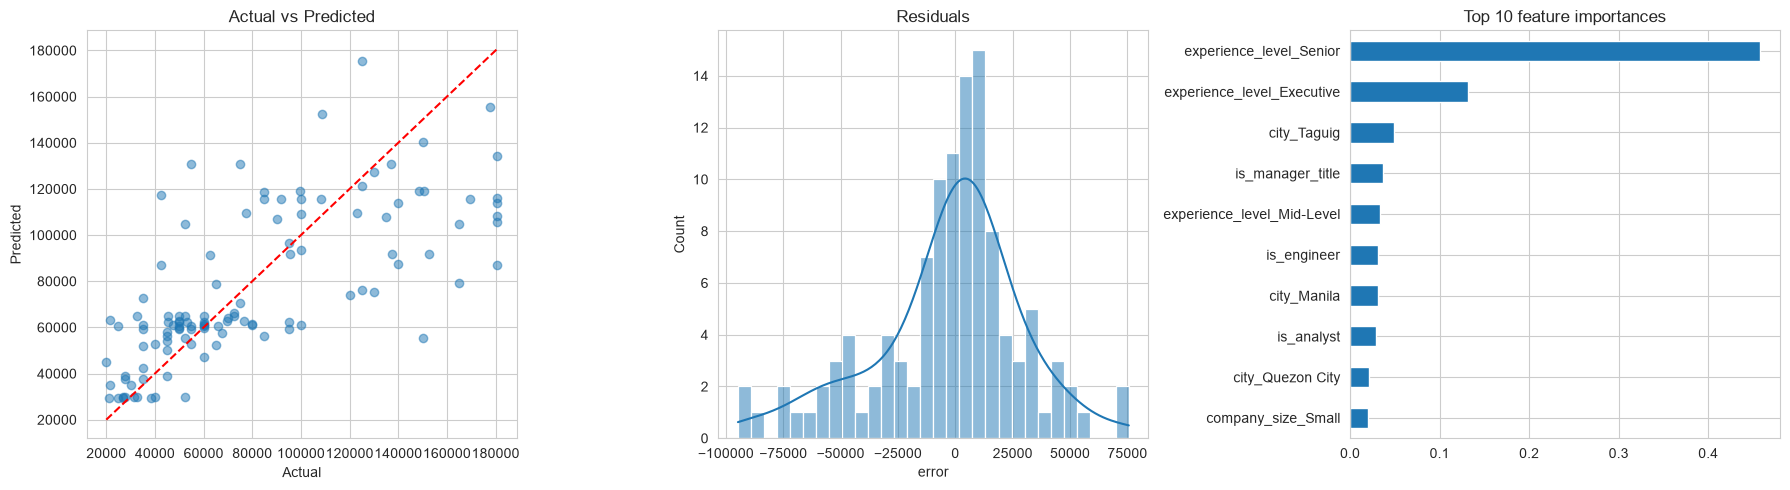

                          mean  count
experience_level                     
Entry-Level        8258.284674     17
Executive         50585.151050      1
Mid-Level         14026.193217     48
Senior            37154.971778     42
Unknown           41337.386781      6


In [18]:
res = pd.DataFrame({"actual": y_test.values, "pred": best_pred})
res["error"] = res["pred"] - res["actual"]

fig, ax = plt.subplots(1, 3, figsize=(18, 5))
ax[0].scatter(res.actual, res.pred, alpha=.5)
ax[0].plot([res.actual.min(), res.actual.max()], [res.actual.min(), res.actual.max()], "r--")
ax[0].set_title("Actual vs Predicted"); ax[0].set_xlabel("Actual"); ax[0].set_ylabel("Predicted")
sns.histplot(res["error"], bins=30, kde=True, ax=ax[1]); ax[1].set_title("Residuals")
imp = pd.Series(best_rf.feature_importances_, index=X_train.columns).sort_values().tail(10)
imp.plot.barh(ax=ax[2], title="Top 10 feature importances")
plt.tight_layout(); plt.show()

test_idx = y_test.index
err_by_exp = (df.loc[test_idx, "experience_level"].to_frame()
              .assign(abs_err=res["error"].abs().values)
              .groupby("experience_level")["abs_err"].agg(["mean", "count"]))
print(err_by_exp)

**Interpretation:** The tuned Random Forest shows a moderate fit (R² ≈ 0.50, RMSE ≈ 32,500 PHP). Residuals are centered near zero but have a longer negative tail, meaning high salaries tend to be underpredicted. Prediction errors are smallest for Entry-Level and Mid-Level roles and largest for Senior, Executive, and Unknown experience levels. The feature importance plot shows that Senior and Executive experience levels are the top drivers of salary, followed by Taguig location and manager job titles.

In [19]:
top = res.assign(abs_error=res["error"].abs()).sort_values("abs_error", ascending=False).head(10)
print(top.round(0))


       actual      pred    error  abs_error
59   150000.0   55249.0 -94751.0    94751.0
108  180625.0   87106.0 -93519.0    93519.0
80   165000.0   79414.0 -85586.0    85586.0
76    55000.0  130613.0  75613.0    75613.0
84   180625.0  105714.0 -74911.0    74911.0
34    42500.0  117300.0  74800.0    74800.0
110  180625.0  108453.0 -72172.0    72172.0
14   180625.0  113892.0 -66733.0    66733.0
43   180625.0  116196.0 -64429.0    64429.0
109  152500.0   91967.0 -60533.0    60533.0


**Interpretation:** Most of the largest errors are underpredictions of very high salaries (150,000–180,625 PHP), where the model predicted only about 55,000–116,000 PHP. A few cases were overpredicted, such as postings with actual salaries of 42,500 and 55,000 PHP that were predicted at above 115,000 PHP. These are likely profiles with unusual salary levels that the available features cannot explain.

---
## Extension Component: Clustering (K-Means)
We applied TF-IDF to the job titles (this changes the words into numbers) and grouped them into 5 clusters with K-Means. Then we compared the salaries of the clusters. The clusters overlap a lot and show only small differences in salary (mean salary of about 69,000–83,000 PHP).

In [20]:
tfidf = TfidfVectorizer(stop_words="english", max_features=300)
T = tfidf.fit_transform(df["job_title"])
km = KMeans(n_clusters=5, random_state=42, n_init=10).fit(T)
df["title_cluster"] = km.labels_

terms = np.array(tfidf.get_feature_names_out())
for i, center in enumerate(km.cluster_centers_):
    print(f"Cluster {i} ({(km.labels_==i).sum()} jobs): {', '.join(terms[center.argsort()[-6:][::-1]])}")
print(df.groupby("title_cluster")["salary_capped"].agg(["mean", "median", "count"]).round(0))

Cluster 0 (36 jobs): information, security, analyst, officer, iso, risk
Cluster 1 (85 jobs): specialist, cyber, security, consultant, cybersecurity, associate
Cluster 2 (253 jobs): soc, analyst, cybersecurity, manager, security, senior
Cluster 3 (113 jobs): engineer, security, cyber, cybersecurity, senior, network
Cluster 4 (79 jobs): analyst, cyber, security, senior, operations, grc
                  mean   median  count
title_cluster                         
0              71254.0  49750.0     36
1              83099.0  75000.0     85
2              78753.0  68500.0    253
3              69283.0  58292.0    113
4              71858.0  62000.0     79


**What we see (clusters):**
- **Cluster 0** (36 jobs): information security, officer, ISO and risk jobs. The median salary is 49,750, the lowest.
- **Cluster 3** (113 jobs): engineer and network jobs. The median is 58,292.
- **Cluster 4** (79 jobs): analyst, operations and GRC jobs. The median is 62,000.
- **Cluster 2** (253 jobs): SOC analyst, manager and senior jobs. This is the biggest cluster. The median is 68,500.
- **Cluster 1** (85 jobs): specialist, consultant and associate jobs. The median is 75,000, the highest.

Next we check the elbow method and the silhouette score for k = 2 to 10.

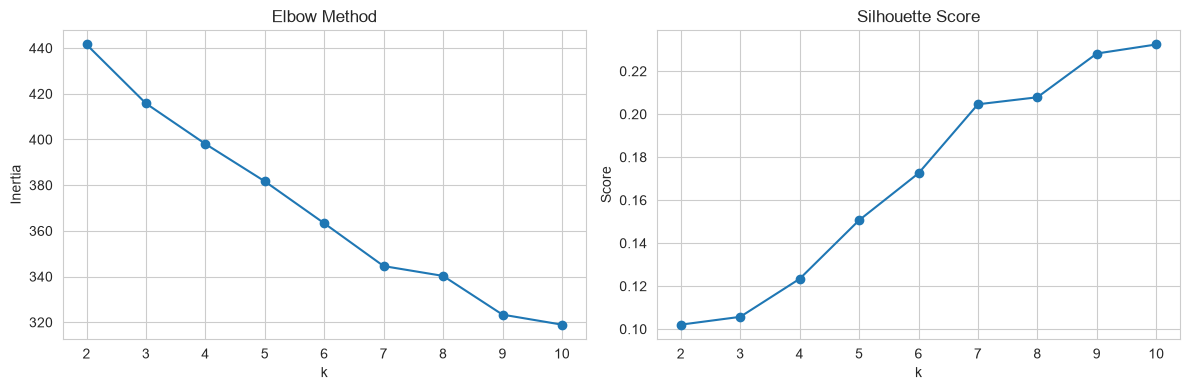

In [21]:
inertias, sils, ks = [], [], range(2, 11)
for k in ks:
    m = KMeans(n_clusters=k, random_state=42, n_init=10).fit(T)
    inertias.append(m.inertia_)
    sils.append(silhouette_score(T, m.labels_))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(ks, inertias, marker="o"); ax[0].set_title("Elbow Method"); ax[0].set_xlabel("k"); ax[0].set_ylabel("Inertia")
ax[1].plot(ks, sils, marker="o"); ax[1].set_title("Silhouette Score"); ax[1].set_xlabel("k"); ax[1].set_ylabel("Score")
plt.tight_layout(); plt.show()

**Interpretation:** The elbow curve declines steadily with no clear elbow, and silhouette scores rise with k but stay low (below 0.25), indicating weak cluster structure. k = 5 was chosen for interpretability (silhouette ≈ 0.15), not because it is statistically optimal.

---
## Stage 9: Model Deployment
- Save the trained model and the scaler (for example with `joblib`). We recommend Linear Regression, because it has the best test score and it is simple.
- Make a simple web page or small app. The user enters the experience level, job type, city, company size and work arrangement, and the app shows the expected monthly salary.
- The app must prepare the input in the same way as the training data: same one-hot columns and same scaler.

---
## Stage 10: Model Monitoring and Maintenance
- **Accuracy:** Every month, compare the predictions with new job posts. Track MSE and MAE. If the MAE becomes much higher than our test MAE (about 22,915 PHP for Linear Regression), we check the model.
- **Data drift:** Compare the new posts with the training data. For example, check the salary distribution, the share of experience levels, and new cities or new job titles.
- **Retraining:** Collect new posts every 3 to 6 months and clean them in the same way. Retrain, and use the new model only if its test MSE is better than the old one. Keep the old model so we can go back.

---
## Ethics, Bias, Privacy and Limitations
- **Bias in the data:** We collected posts by hand from job sites and  agencies. Many posts do not show a salary (686 of 1,542 raw rows had no salary), and companies that show their salary may be different from companies that do not. There are very few Remote (5) and Hybrid (11) posts.
- **City list problem:** Our city list counts many "<city>, Metro Manila" posts as Manila (see Stage 4, the city chart). So the Manila group is too big and the city results are less reliable.
- **Posted salary is not real salary:** The salary in a job post is not always what the person really gets.
- **Duplicates:** The same job can be posted on many sites. We removed only exact duplicate rows, so some repeats may stay.
- **Privacy:** The data has no personal information. It only has company names and job details from public posts.
- **Licensing:** The data was collected by hand for school use. We follow the terms of each site, and we do not sell or republish the data.
- **Misuse:** The model should not be used to decide how much to pay a person, or to push salaries down. It is only a rough guide.
- **Model limits:** R2 is about 0.54, so almost half of the changes in salary are not explained. The mistakes are bigger for senior and high-paying jobs.
- **Near-duplicate posts:** We removed only exact duplicate rows. The same job may still appear more than once if it was posted on different websites, so a similar post may be in both the training and the test set.
- **Posting year:** “Almost all posts (1,478 of 1,542, or 95.9%) are from 2026, so the model may not fit salaries from other years.”

---
## Summary
- We cleaned 1,542 raw rows to 566 model-ready rows for NCR (240 companies).
- Experience level is the main factor for salary (correlation 0.69).
- The best model is Linear Regression (MSE 985,070,101, RMSE 31,386, R2 0.536 on the test set).
- The models are weaker for high-paying jobs. More data and more features (skills, certifications) would help.